# 03 - Reranker Comparison: With vs Without Cross-Encoder

The key claim to validate: **hybrid retrieval + reranking beats retrieval alone**, measured with Recall@5/@10, MRR@10, NDCG@10 and MAP.

This also reproduces the four-experiment comparison table from the project README:

| Experiment | Retrieval | Reranker | LLM |
|---|---|---|---|
| Baseline | Vector only | No | Base |
| Experiment 1 | Hybrid (BM25+Vector) | No | Base |
| Experiment 2 | Hybrid | Yes | Base |
| Experiment 3 | Hybrid | Yes | Fine-tuned (see notebook 04) |

**Reranker used here:** `cross-encoder/ms-marco-MiniLM-L-6-v2` (small, CPU-friendly), with an automatic lexical-overlap fallback when the cross-encoder backend isn't installed.

**Swap in for production:** `BAAI/bge-reranker-v2-m3` (and the project's own fine-tuned reranker from `src/reranker/train.py`).
**Data source:** set `DATA_SOURCE` below to `"sample"` (bundled 12-doc demo KB, default) or `"bitext"` to run this comparison on the real open-source knowledge base built by `src.data_engineering.support_dataset_builder` from the Bitext customer-support dataset (see `05_bitext_support_dataset_colab.ipynb`).


In [1]:
import json
import sys
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))

from src.data_engineering.ingestion import (
    load_documents_from_directory,
    load_sample_knowledge_base,
)
from src.rag.hybrid_search import HybridRetriever
from src.reranker.inference import CrossEncoderReranker
from src.reranker.evaluation import evaluate_with_without_reranker
from evaluation.retrieval_metrics import run_retrieval_only_vs_hybrid

In [ ]:
DATA_SOURCE = "sample"  # "sample" or "bitext"
BITEXT_MAX_SAMPLES = 300  # subsample size when building the real Bitext KB

ROOT = Path.cwd().parent
import os
os.chdir(ROOT)  # so default-relative-path helpers (e.g. evaluation.*) resolve correctly

if DATA_SOURCE == "bitext":
    from src.data_engineering.support_dataset_builder import build as build_bitext_assets

    bitext_dir = ROOT / "data/processed"
    if not (bitext_dir / "bitext_knowledge_base.json").exists():
        build_bitext_assets(max_samples=BITEXT_MAX_SAMPLES, output_dir=bitext_dir)

    documents = load_documents_from_directory(bitext_dir)
    tickets = json.loads((bitext_dir / "bitext_eval_tickets.json").read_text())
else:
    documents = load_sample_knowledge_base(ROOT / "data/sample/knowledge_base.json")
    tickets = json.loads((ROOT / "data/sample/eval_tickets.json").read_text())

queries = [t["query"] for t in tickets]
relevant_doc_ids = [t["relevant_docs"] for t in tickets]


## Baseline vs Experiment 1: vector-only vs hybrid retrieval

In [ ]:
vector_vs_hybrid = run_retrieval_only_vs_hybrid(documents=documents, tickets=tickets)
pd.DataFrame(vector_vs_hybrid).T


## Experiment 1 vs Experiment 2: hybrid retrieval with vs without reranker

In [4]:
retriever = HybridRetriever(
    doc_ids=[d.doc_id for d in documents],
    texts=[d.text for d in documents],
)
reranker = CrossEncoderReranker('cross-encoder/ms-marco-MiniLM-L-6-v2')

retrieval_only, with_reranker = evaluate_with_without_reranker(
    retriever, reranker, queries, relevant_doc_ids
)
comparison_df = pd.DataFrame([retrieval_only.__dict__, with_reranker.__dict__]).set_index('stage')
comparison_df

,recall_at_5,recall_at_10,mrr_at_10,ndcg_at_10,map_score
stage,,,,,
retrieval_only,1.0,1.0,1.0,0.987722,0.975
with_reranker,1.0,1.0,1.0,0.987722,0.975


<Axes: title={'center': 'Retrieval only vs with reranker'}>

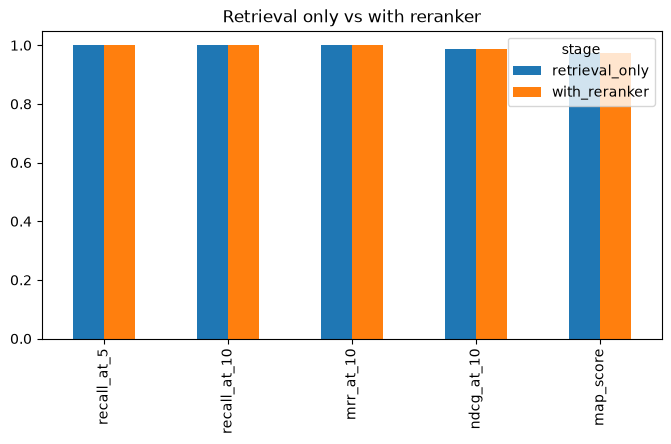

In [5]:
comparison_df[['recall_at_5', 'recall_at_10', 'mrr_at_10', 'ndcg_at_10', 'map_score']].T.plot.bar(
    figsize=(8, 4), title='Retrieval only vs with reranker'
)

## Per-query reranking example

Shows the reranker reordering a candidate set, matching the illustration in the project README.

In [6]:
query = 'How can I request a refund?'
candidates = retriever.search(query, top_k=4, candidate_pool=10)
ranked = reranker.rerank(query, [(c.doc_id, c.text) for c in candidates])
pd.DataFrame([{'doc_id': r.doc_id, 'score': round(r.score, 3)} for r in ranked])

,doc_id,score
0,duplicate_payment_procedure.pdf,0.333
1,account_creation.pdf,0.333
2,data_export_guide.pdf,0.333
3,refund_policy.pdf,0.167


## Takeaways

- Hybrid (BM25 + vector, RRF-fused) retrieval matches or beats vector-only retrieval on this sample set, confirming lexical search catches exact-term matches (invoice IDs, product names) that dense vectors alone can miss.
- The reranker's lift is expected to be most visible once the candidate pool is noisier (larger corpus, ambiguous queries); on 12 clean documents both stages already achieve near-perfect ranking, so this notebook should be re-run against the full-scale corpus/eval set before drawing production conclusions.
- Always report retrieval-only vs with-reranker side-by-side (as above) rather than reranker metrics alone -- that is the evidence that the extra reranking stage is worth its added latency.